In [18]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    root_mean_squared_error,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from xgboost import XGBClassifier

# Configure display settings
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

In [19]:
df = pd.read_csv("data/spotify_tracks.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [20]:
features = [
    'track_genre', 'explicit', 'key', 'mode', 'time_signature', 
    'duration_ms', 'energy', 'speechiness', 'acousticness', 
    'instrumentalness', 'liveness', 'valence', 'tempo',
    'danceability', 'loudness' 
]
target_col = 'popularity'
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [21]:
#  Set the High Popularity (Score >= 50)
df['target'] = (df[target_col] >= 50).astype(int)

# duration_range is the continuous song length in milliseconds (duration_ms)
# short (0-2min or 0 to 120,000 ms), medium (2-4 minutes or 120,000 to 240,000 ms and long > 4 minutes or 240,000 ms)
df['duration_range'] = pd.cut(df['duration_ms'], bins=[0, 120000, 240000, np.inf], labels=['short', 'medium', 'long']).astype(str)

# sound to energy ratio
df['acoustic_energy_ratio'] = df['acousticness'] / (df['energy'] + 1e-5)
extended_features = features + ['duration_range', 'acoustic_energy_ratio']

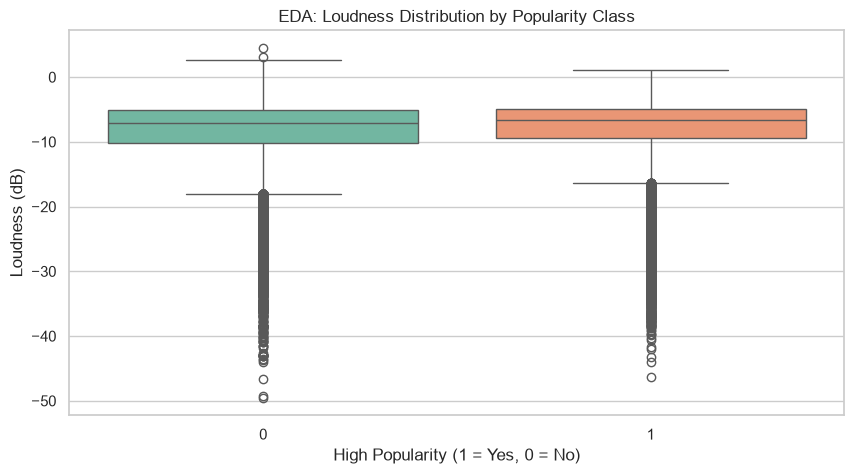

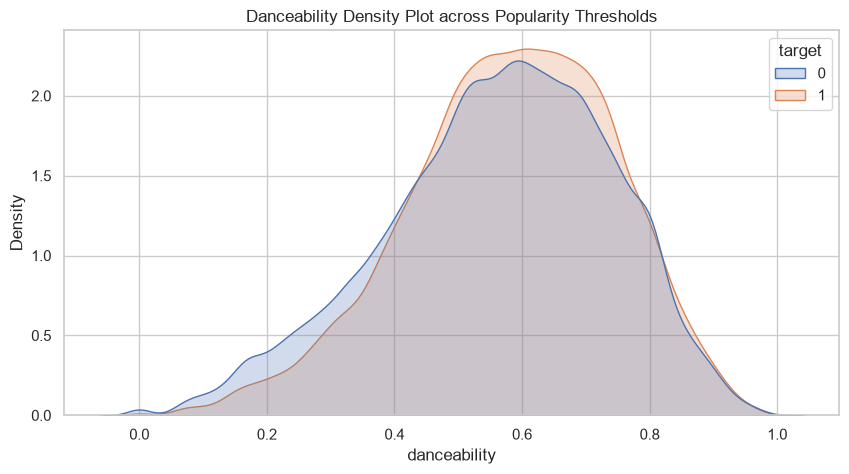

In [22]:
# EDA 
plt.figure(figsize=(10, 5))
sns.boxplot(x='target', y='loudness', hue='target', data=df, palette='Set2', legend=False)
plt.title('EDA: Loudness Distribution by Popularity Class')
plt.xlabel('High Popularity (1 = Yes, 0 = No)')
plt.ylabel('Loudness (dB)')
plt.show()

plt.figure(figsize=(10, 5))
sns.kdeplot(data=df, x='danceability', hue='target', common_norm=False, fill=True)
plt.title('Danceability Density Plot across Popularity Thresholds')
plt.show()

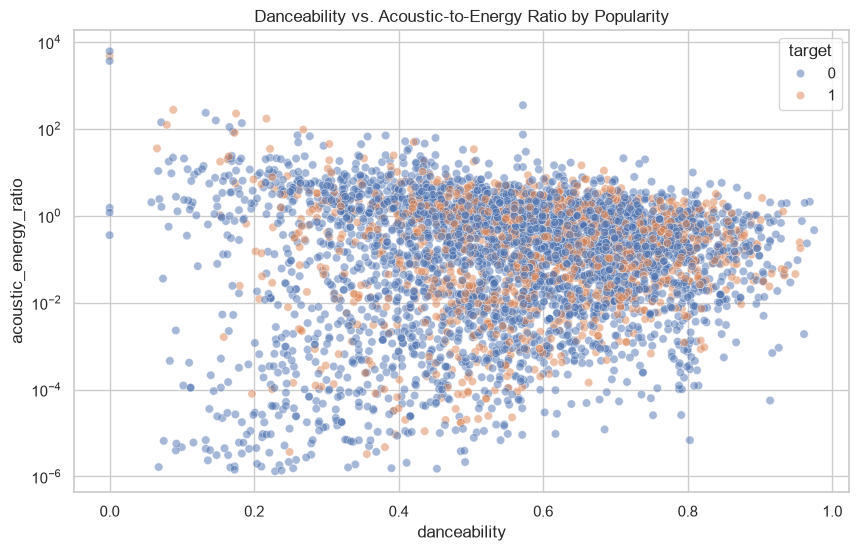

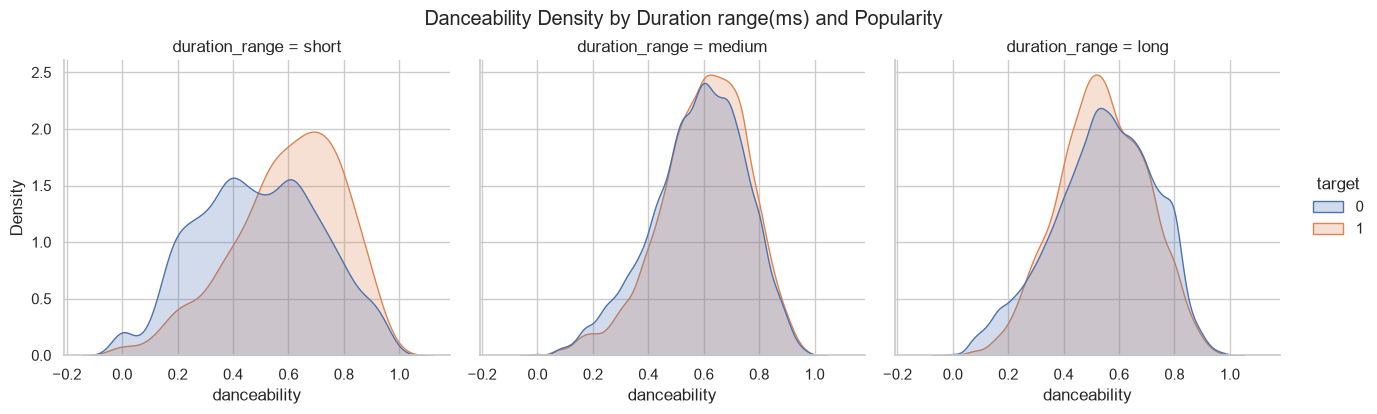

danceability             1.000000
valence                  0.477341
loudness                 0.259077
time_signature           0.207218
energy                   0.134325
explicit                 0.122507
speechiness              0.108626
key                      0.036469
popularity               0.035448
tempo                   -0.050450
acoustic_energy_ratio   -0.060301
mode                    -0.069219
duration_ms             -0.073426
liveness                -0.131617
acousticness            -0.171533
instrumentalness        -0.185606
Name: danceability, dtype: float64


In [24]:
# EDA - exploratory data analysis
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df.sample(5000, random_state=42),
    x='danceability',
    y='acoustic_energy_ratio',
    hue='target',
    alpha=0.5
)
plt.yscale('log') 
plt.title('Danceability vs. Acoustic-to-Energy Ratio by Popularity')
plt.show()

g = sns.displot(
    data=df,
    x='danceability',
    hue='target',
    col='duration_range',
    col_order=['short', 'medium', 'long'],
    kind='kde',
    common_norm=False,
    fill=True,
    height=4,
    aspect=1.1
)
g.fig.suptitle('Danceability Density by Duration range(ms) and Popularity', y=1.03)
plt.show()

numeric_cols = [c for c in extended_features if df[c].dtype != 'object'] + ['popularity']
corr_with_dance = df[numeric_cols].corr()['danceability'].sort_values(ascending=False)
print(corr_with_dance)

In [25]:
# Split data into train and validation sets
df_train, df_val = train_test_split(df, test_size=0.2, random_state=42, stratify=df['target'])
y_train = df_train['target'].values
y_val = df_val['target'].values

# Convert dataframes to dictionaries for DictVectorizer
train_dicts = df_train[extended_features].to_dict(orient='records')
val_dicts = df_val[extended_features].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

In [9]:
# Evaluate Logistic Regression with scaled data
lr_model = LogisticRegression(max_iter=2000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_val_scaled)
y_prob_lr = lr_model.predict_proba(X_val_scaled)[:, 1]
print("--- Logistic Regression Performance ---")
print(f"ROC-AUC: {roc_auc_score(y_val, y_prob_lr):.4f}")
print(f"F1-Score: {f1_score(y_val, y_pred_lr):.4f}")
print("\nClassification Report:\n", classification_report(y_val, y_pred_lr))

--- Logistic Regression Performance ---
ROC-AUC: 0.8078
F1-Score: 0.4463

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.93      0.86     16927
           1       0.62      0.35      0.45      5873

    accuracy                           0.78     22800
   macro avg       0.71      0.64      0.65     22800
weighted avg       0.76      0.78      0.75     22800



In [26]:
# Initialize, train and evaluate XGBoost Classifier
xgb_model = XGBClassifier(
    n_estimators=150, 
    learning_rate=0.05, 
    max_depth=6, 
    random_state=42, 
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_val)
y_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]

print("--- XGBoost Performance ---")
print(f"ROC-AUC: {roc_auc_score(y_val, y_prob_xgb):.4f}")
print(f"F1-Score: {f1_score(y_val, y_pred_xgb):.4f}")
print("\nClassification Report:\n", classification_report(y_val, y_pred_xgb))

--- XGBoost Performance ---
ROC-AUC: 0.8100
F1-Score: 0.2823

Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.98      0.87     16927
           1       0.78      0.17      0.28      5873

    accuracy                           0.77     22800
   macro avg       0.78      0.58      0.57     22800
weighted avg       0.78      0.77      0.72     22800



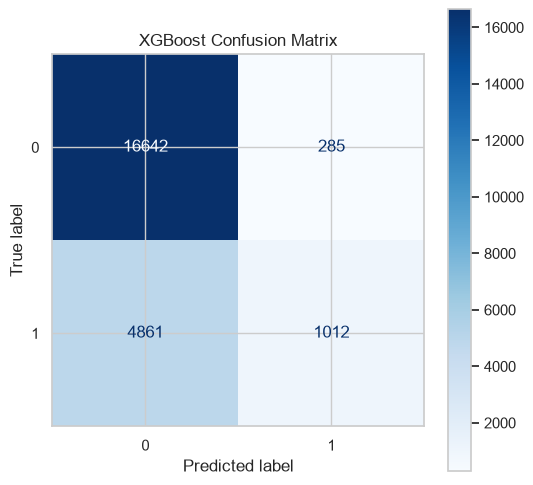

['models/spotify_xgb_model.pkl']

In [27]:
# Confusion Matrix for XGBoost
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_xgb, ax=ax, cmap='Blues', values_format='d')
plt.title('XGBoost Confusion Matrix')
plt.show()
joblib.dump(dv, 'dict_vectorizer.pkl')
joblib.dump(xgb_model, 'models/spotify_xgb_model.pkl')

In [28]:
os.makedirs("models", exist_ok=True)
spotify_artifact = {"dv": dv,"model": xgb_model,"features": extended_features,"target_definition": "High Popularity (Score >= 50)"}
joblib.dump(spotify_artifact, 'models/spotify_xgb_model.pkl')

['models/spotify_xgb_model.pkl']

In [29]:
artifact = joblib.load("models/spotify_xgb_model.pkl")
print("Artifact Keys:", list(artifact.keys()))
print("\nTarget Definition:", artifact["target_definition"])
print("\nFeatures Used:", artifact["features"])
print("\n XGBoost model parameters- Model Details:")
print(artifact["model"])

Artifact Keys: ['dv', 'model', 'features', 'target_definition']

Target Definition: High Popularity (Score >= 50)

Features Used: ['track_genre', 'explicit', 'key', 'mode', 'time_signature', 'duration_ms', 'energy', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'danceability', 'loudness', 'duration_range', 'acoustic_energy_ratio']

 XGBoost model parameters- Model Details:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=Non